# 09 — What drives the predictions, and what a developer would do with them

This notebook explains the models — hazard ratios of the Cox models (F6),
SHAP values and partial dependence of the discrete-time LightGBM's
P(operation within 5 years) (F7) — checks them against facts known from
outside the model, and turns the predictions into a ranked table for a
book of 25 requests with three worked examples.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/cox_hazard_ratios.csv` | notebook 05 — cause-specific hazard ratios |
| in | `data/interim/trackA.parquet`, `data/interim/queue_clean.parquet`, `results/dt_tuning.json` | notebooks 02, 04, 06 — to refit the final LightGBM |
| in | `data/processed/predictions_trackA.parquet` | notebooks 05–06 — stored predictions (check) and the baseline |
| in | `results/benchmarks.csv` | notebook 03 — LBNL facts reproduced from the file |
| out | `results/shap_values.csv`, `results/partial_dependence.csv` | SHAP values of P(operation by 5 yr) for a sample of test requests; partial-dependence curves |
| out | `results/sanity_checks.csv` | outside facts recovered or not |
| out | `results/ranking_table.csv`, `results/worked_examples.csv`, `results/explain_checks.csv` | the 25-request book, three worked examples, checks |
| out | `figures/F6_*.png|svg`, `figures/F7_*.png|svg`, `figures/09_explain_and_rank/*.png|svg`, `report/figure_notes.md` | report figures F6, F7 and exploratory figures |

## Setup

`src/explain.py` encodes the entry-time features as numbers
(`encode` / `decode`) and wraps the whole chain of the discrete-time
LightGBM — ten yearly rows, hazards, cumulative incidence — as one function
of those features (`incidence_function`). SHAP's permutation explainer and
the partial-dependence curves call that function, so every explanation is
in the unit a developer reads: probability points of P(operation within t
years).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, discrete_time, explain, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "09_explain_and_rank"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/09_explain_and_rank/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"

import time
import warnings

import shap

warnings.filterwarnings("ignore", category=FutureWarning)
START = time.time()
HORIZONS = config.HORIZONS
H = 5  # horizon explained: the middle one, fully observed for every test request
N_EXPLAIN, N_BACKGROUND = 300, 100  # test requests explained; background requests for the SHAP baseline
FEATURE_LABELS = {"region": "Region", "state": "State", "tech": "Technology", "hybrid": "Hybrid",
                  "size_mw": "Size (MW)", "service": "Service type", "q_year": "Request year",
                  "congestion_gw": "GW waiting at entry", "congestion_rank": "Congestion rank at entry"}
NUMERIC = ["size_mw", "q_year", "congestion_gw", "congestion_rank"]


def lower_first(text):
    """Feature label for use inside a sentence (first letter lower case, units kept)."""
    return text[0].lower() + text[1:]

## 1. Hazard ratios: which attributes speed operation or withdrawal (F6)

The cause-specific Cox models of notebook 05 give each attribute one hazard
ratio for operation and one for withdrawal (main version, ERCOT delayed
entry). A ratio above 1 means requests with the attribute reach that exit
faster at every point in the wait than the reference request (PJM, solar,
20–100 MW, NRIS). Notebook 05 found that 17 of 36 effects are not constant
over the wait, so each ratio is an average over the wait; the discrete-time
models below let effects change with time.

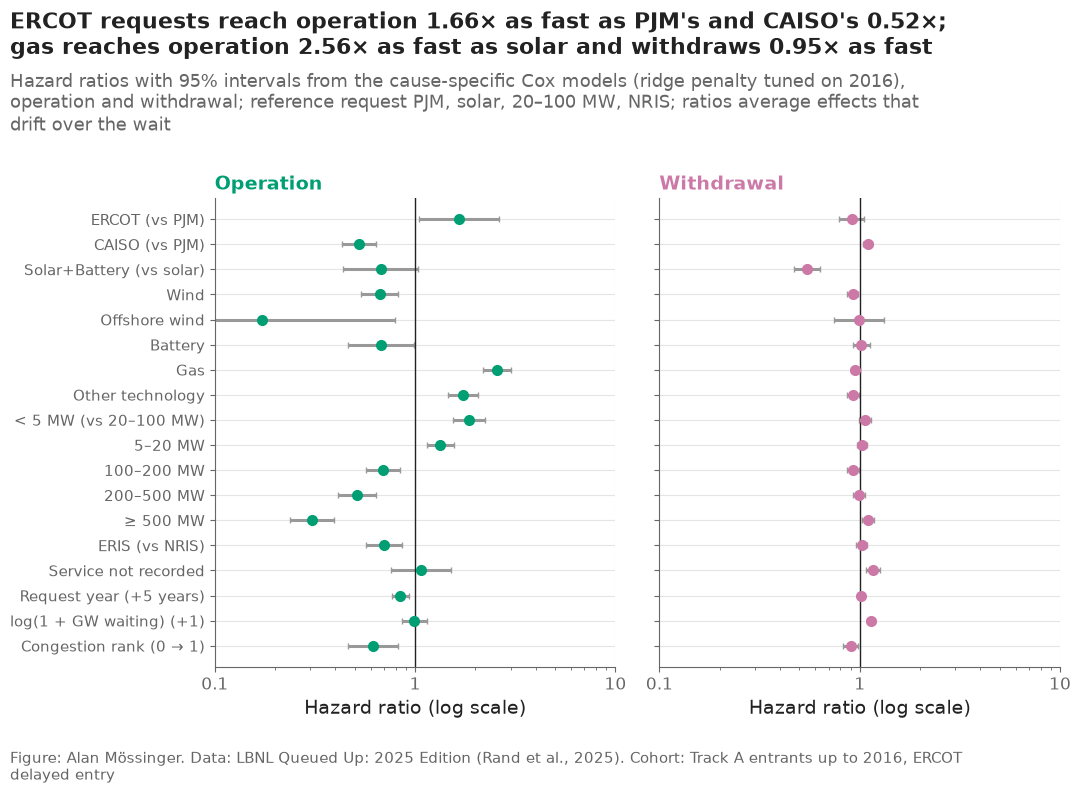

cause,operation,withdrawal
covariate,,
region_ERCOT,1.66,0.91
region_CAISO,0.52,1.10
tech_Solar+Battery,0.67,0.55
tech_Wind,0.67,0.92
tech_Offshore Wind,0.17,0.99
tech_Battery,0.68,1.02
tech_Gas,2.56,0.95
tech_Other,1.74,0.93
size_<5,1.85,1.06


In [2]:
hr = pd.read_csv(paths.RESULTS / "cox_hazard_ratios.csv")
hr = hr[hr["version"].str.startswith("main")]
COX_LABELS = {"region_ERCOT": "ERCOT (vs PJM)", "region_CAISO": "CAISO (vs PJM)",
              "tech_Solar+Battery": "Solar+Battery (vs solar)", "tech_Wind": "Wind", "tech_Offshore Wind": "Offshore wind",
              "tech_Battery": "Battery", "tech_Gas": "Gas", "tech_Other": "Other technology",
              "size_<5": "< 5 MW (vs 20–100 MW)", "size_5–<20": "5–20 MW", "size_100–<200": "100–200 MW",
              "size_200–<500": "200–500 MW", "size_≥500": "≥ 500 MW", "service_ERIS": "ERIS (vs NRIS)",
              "service_missing": "Service not recorded", "q_year_5": "Request year (+5 years)",
              "log_congestion_gw": "log(1 + GW waiting) (+1)", "congestion_rank": "Congestion rank (0 → 1)"}
labels = list(COX_LABELS.values())
y_pos = {label: len(labels) - 1 - i for i, label in enumerate(labels)}
fig, axes = plt.subplots(1, 2, sharey=True, figsize=(11, 8))
for ax, cause in zip(axes, ["operation", "withdrawal"]):
    part = hr[hr["cause"] == cause].set_index("covariate").loc[list(COX_LABELS)]
    y = [y_pos[COX_LABELS[c]] for c in part.index]
    color = config.OUTCOME_COLORS[cause]
    ax.errorbar(part["hazard_ratio"], y, xerr=[part["hazard_ratio"] - part["ci_low"], part["ci_high"] - part["hazard_ratio"]],
                fmt="o", color=color, ecolor="#999999", capsize=2, markersize=7)
    ax.axvline(1, color=plots.INK, linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(0.1, 10)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
    ax.set_title(f"{cause.capitalize()}", color=color)
    ax.set_xlabel("Hazard ratio (log scale)")
axes[0].set_yticks(list(y_pos.values()), list(y_pos.keys()), fontsize=11)
op = hr[hr["cause"] == "operation"].set_index("covariate")["hazard_ratio"]
wd = hr[hr["cause"] == "withdrawal"].set_index("covariate")["hazard_ratio"]
plots.finish(fig,
             f"ERCOT requests reach operation {op['region_ERCOT']:.2f}× as fast as PJM's and CAISO's {op['region_CAISO']:.2f}×; "
             f"gas reaches operation {op['tech_Gas']:.2f}× as fast as solar and withdraws {wd['tech_Gas']:.2f}× as fast",
             "Hazard ratios with 95% intervals from the cause-specific Cox models (ridge penalty tuned on 2016), operation and "
             "withdrawal; reference request PJM, solar, 20–100 MW, NRIS; ratios average effects that drift over the wait",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}, ERCOT delayed entry")
plots.save_fig(fig, "F6_hazard_ratios", "Hazard ratios for operation and withdrawal from the cause-specific Cox models, main version.", NOTEBOOK)
plt.show()
hr.pivot_table(index="covariate", columns="cause", values="hazard_ratio").loc[list(COX_LABELS)].round(2)

**Reading this.** For reaching operation, the Cox model's largest effects are technology, size and region: gas 2.56× as fast as solar, other technologies 1.74×, offshore wind 0.17×; requests under 5 MW 1.85× and 5–20 MW 1.34× as fast as 20–100 MW, falling to 0.31× at 500 MW or more; ERCOT 1.66× and CAISO 0.52× PJM. For withdrawal the ratios cluster near 1: the attributes known at entry say much more about how fast a request is built than about how fast it drops out. The exceptions are Solar+Battery hybrids, which withdraw at 0.55× solar's rate, and queue crowding: each unit of log(1 + GW waiting) raises the withdrawal hazard 1.14× while leaving operation unchanged (0.99). A request placed late in a long queue (congestion rank 0 → 1) operates at 0.61× the rate. For a developer the reading is that small size and gas are the two attributes most associated with quick completion; for a regulator, that crowding shows up as faster withdrawal rather than slower building. Caveat from notebook 05: 17 of 36 effects are not constant over the wait, so each ratio is an average.

## 2. The model being explained

The final discrete-time LightGBM is refitted on entrants to 2016 with
notebook 06's settings (`discrete_time.fit_both`), and the explanation
function is checked against the predictions stored by notebook 06: they
must agree exactly, or the explanations would describe a different model.

In [3]:
clean = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
track_a = pd.read_parquet(paths.DATA_INTERIM / "trackA.parquet")
track_a["tech"] = track_a["type_clean"].map(plots.tech_group)
tuning = json.loads((paths.RESULTS / "dt_tuning.json").read_text(encoding="utf-8"))
final = track_a[track_a["q_year"] <= config.TRAIN_MAX_YEAR]
test = track_a[track_a["q_year"].between(*config.TEST_YEARS)].copy()
fitted = discrete_time.fit_both(final, clean, tuning)
STATES = sorted(track_a["state"].astype(str).unique())
f = {h: explain.incidence_function(fitted, STATES, h) for h in HORIZONS}
X_test = explain.encode(test, STATES)
pred = pd.read_parquet(paths.DATA_PROCESSED / "predictions_trackA.parquet")
stored = {h: pred[(pred["split"] == "test") & (pred["horizon"] == h)].set_index("project_key").loc[test["project_key"].astype(str)]
          for h in HORIZONS}
gap = max(float(np.abs(f[h](X_test.to_numpy()) - stored[h]["dt_lgbm"].to_numpy()).max()) for h in HORIZONS)
print(f"largest gap between the explanation function and notebook 06's stored predictions: {gap:.1e}")
print(f"test requests: {len(test):,}; encoded features: {list(X_test.columns)}")

largest gap between the explanation function and notebook 06's stored predictions: 0.0e+00
test requests: 2,268; encoded features: ['region', 'state', 'tech', 'hybrid', 'size_mw', 'service', 'q_year', 'congestion_gw', 'congestion_rank']


## 3. SHAP values of P(operation within 5 years) (F7)

SHAP splits each request's prediction into a contribution per feature:
the prediction equals the average prediction over a background set plus the
sum of the contributions. The background is 100 random test requests, so a
contribution reads "how far this feature moves the request away from a
typical 2017–2019 request", in probability points. 300 test requests are
explained with the permutation explainer (two permutations, each run forward
and backward). Region and state, and size and size regime, move together;
SHAP's independent masking can pair a Texas state with PJM, so the split
between region and state should be read loosely, their sum less so.

In [4]:
rng = np.random.default_rng(9)
background = X_test.iloc[rng.choice(len(X_test), N_BACKGROUND, replace=False)].to_numpy()
explained_idx = rng.choice(len(X_test), N_EXPLAIN, replace=False)
explainer = shap.PermutationExplainer(f[H], shap.maskers.Independent(background, max_samples=N_BACKGROUND), seed=9)
max_evals = 2 * (2 * len(explain.FEATURES) + 1)


def shap_of(X):
    """SHAP values of P(operation by H) for the rows of an encoded feature table."""
    return explainer(X.to_numpy(), max_evals=max_evals, silent=True)


sv = shap_of(X_test.iloc[explained_idx])
shap_table = pd.DataFrame(sv.values, columns=explain.FEATURES, index=X_test.index[explained_idx])
explained = test.loc[shap_table.index]
additivity = float(np.abs(sv.values.sum(axis=1) + sv.base_values - f[H](X_test.iloc[explained_idx].to_numpy())).max())
shap_out = shap_table.add_prefix("shap_").assign(project_key=explained["project_key"].astype(str).to_numpy(),
                                                 region=explained["region"].astype(str).to_numpy(),
                                                 prediction=f[H](X_test.iloc[explained_idx].to_numpy()))
shap_out.to_csv(paths.RESULTS / "shap_values.csv", index=False)
mean_abs = shap_table.abs().mean().sort_values(ascending=False)
print(f"SHAP baseline (mean prediction of the background): {sv.base_values[0]:.3f}; additivity gap {additivity:.1e}; "
      f"{(time.time() - START) / 60:.1f} minutes so far")
(100 * mean_abs).round(2).rename("mean |SHAP|, points")

SHAP baseline (mean prediction of the background): 0.124; additivity gap 1.3e-15; 3.4 minutes so far


state              5.12
size_mw            3.68
tech               2.95
congestion_gw      1.90
congestion_rank    1.61
service            1.24
region             0.44
hybrid             0.15
q_year             0.00
Name: mean |SHAP|, points, dtype: float64

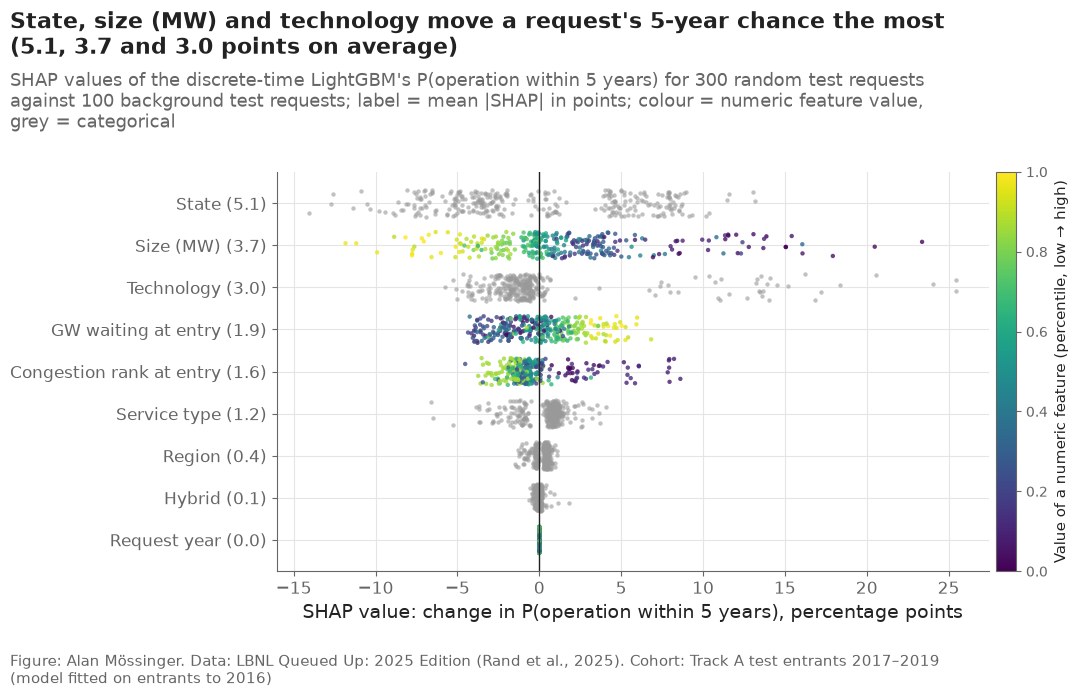

In [5]:
fig, ax = plt.subplots(figsize=(11, 7))
order = list(mean_abs.index[::-1])
cmap = plt.get_cmap("viridis")
for i, feature in enumerate(order):
    values = shap_table[feature].to_numpy() * 100
    jitter = rng.uniform(-0.32, 0.32, len(values))
    if feature in NUMERIC:
        level = X_test.loc[shap_table.index, feature].rank(pct=True).to_numpy()
        ax.scatter(values, i + jitter, c=level, cmap=cmap, vmin=0, vmax=1, s=10, alpha=0.8, linewidths=0)
    else:
        ax.scatter(values, i + jitter, color="#999999", s=10, alpha=0.6, linewidths=0)
ax.axvline(0, color=plots.INK, linewidth=1)
ax.set_yticks(range(len(order)), [f"{FEATURE_LABELS[c]} ({100 * mean_abs[c]:.1f})" for c in order])
ax.set_xlabel("SHAP value: change in P(operation within 5 years), percentage points")
bar = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap), ax=ax, pad=0.01, fraction=0.03)
bar.set_label("Value of a numeric feature (percentile, low → high)", fontsize=11)
bar.ax.tick_params(labelsize=10)
plots.finish(fig,
             f"{FEATURE_LABELS[mean_abs.index[0]]}, {lower_first(FEATURE_LABELS[mean_abs.index[1]])} and "
             f"{lower_first(FEATURE_LABELS[mean_abs.index[2]])} move a request's 5-year chance the most "
             f"({100 * mean_abs.iloc[0]:.1f}, {100 * mean_abs.iloc[1]:.1f} and {100 * mean_abs.iloc[2]:.1f} points on average)",
             f"SHAP values of the discrete-time LightGBM's P(operation within 5 years) for {N_EXPLAIN} random test requests "
             f"against {N_BACKGROUND} background test requests; label = mean |SHAP| in points; colour = numeric feature value, "
             "grey = categorical",
             "Track A test entrants 2017–2019 (model fitted on entrants to 2016)")
plots.save_fig(fig, "F7_shap_summary", "SHAP values of P(operation within 5 years) from the discrete-time LightGBM, 300 test requests.", NOTEBOOK)
plt.show()

**Reading this.** Averaged over 300 test requests, state moves a request's 5-year chance the most (5.12 points), then size (3.68), technology (2.95), GW waiting at entry (1.90), congestion rank (1.61) and service type (1.24); region alone adds 0.44, the hybrid flag 0.15 and the request year 0.00. The contributions add up exactly to each prediction minus the background mean of 12.4% (largest gap 1.3e-15). Small requests (dark points) push predictions up by as much as 20–25 points, very large ones down by up to 12. Two readings matter for the report. First, state and region overlap: region's level sits mostly in the state feature (section 5). Second, the request year contributes nothing because every test request entered after the last training year (2016), and trees give every year beyond that the value of 2016 — the model cannot see that queues kept slowing down, the drift notebook 08 measured.

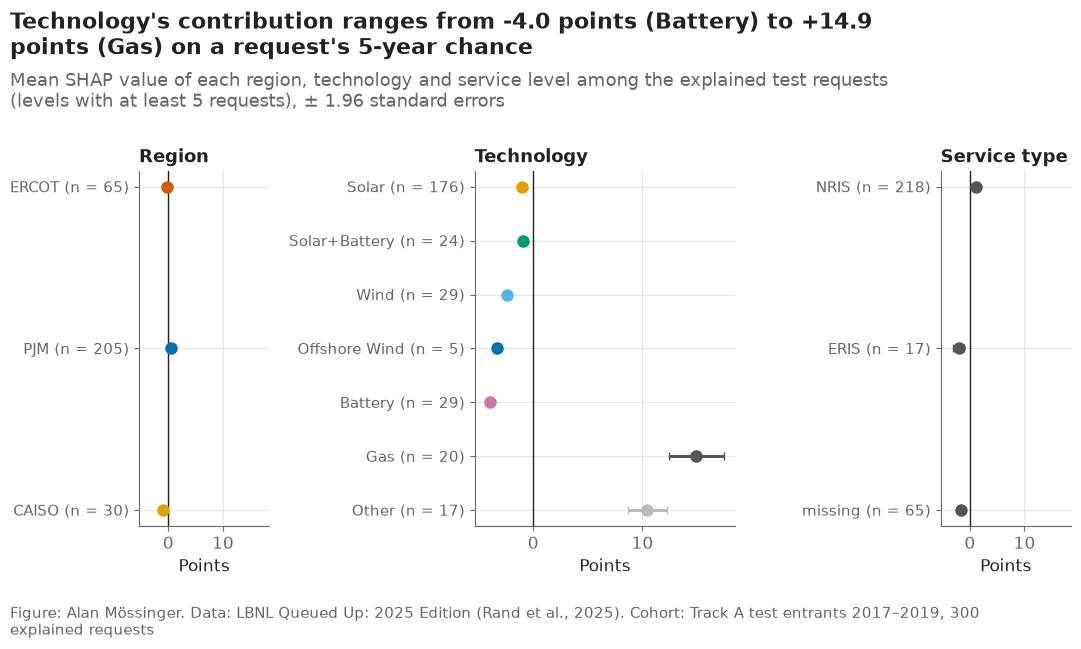

,feature,level,n,mean_shap_points
0,region,ERCOT,65,-0.20
1,region,PJM,205,0.44
2,region,CAISO,30,-0.92
3,tech,Solar,176,-1.00
4,tech,Solar+Battery,24,-0.95
5,tech,Wind,29,-2.38
6,tech,Offshore Wind,5,-3.32
7,tech,Battery,29,-3.95
8,tech,Gas,20,14.94
9,tech,Other,17,10.47


In [6]:
fig, axes = plt.subplots(1, 3, sharex=True, gridspec_kw={"width_ratios": [3, 6, 3]})
cat_rows = []
for ax, feature in zip(axes, ["region", "tech", "service"]):
    levels = explain.CATEGORIES[feature]
    for j, level in enumerate(levels):
        mask = explained[feature].astype(str).to_numpy() == level
        if mask.sum() < 5:
            continue
        values = shap_table.loc[mask, feature] * 100
        se = values.std(ddof=1) / np.sqrt(mask.sum())
        color = plots.region_color(level) if feature == "region" else config.TECH_COLORS.get(level, "#555555")
        ax.errorbar(values.mean(), j, xerr=1.96 * se, fmt="o", color=color, capsize=3, markersize=8)
        cat_rows.append({"feature": feature, "level": level, "n": int(mask.sum()), "mean_shap_points": values.mean()})
    ax.axvline(0, color=plots.INK, linewidth=1)
    ax.set_yticks(range(len(levels)), [f"{lv} (n = {(explained[feature].astype(str) == lv).sum()})" for lv in levels], fontsize=10.5)
    ax.invert_yaxis()
    ax.set_title(FEATURE_LABELS[feature], fontsize=13)
    ax.set_xlabel("Points", fontsize=12)
cats = pd.DataFrame(cat_rows)
t = cats[cats["feature"] == "tech"].set_index("level")["mean_shap_points"]
plots.finish(fig,
             f"Technology's contribution ranges from {t.min():+.1f} points ({t.idxmin()}) to {t.max():+.1f} points ({t.idxmax()}) "
             "on a request's 5-year chance",
             "Mean SHAP value of each region, technology and service level among the explained test requests (levels with "
             "at least 5 requests), ± 1.96 standard errors",
             "Track A test entrants 2017–2019, 300 explained requests")
save(fig, "09_01_shap_by_category", "Mean SHAP contribution of each region, technology and service level to P(operation within 5 years).")
plt.show()
cats.round(2)

**Reading this.** Gas adds 14.94 points on average to a request's 5-year chance (20 explained requests) and other technologies 10.47; batteries subtract 3.95, wind 2.38, solar 1.00 and Solar+Battery 0.95. NRIS requests gain 1.04 points while ERIS (−2.08) and requests without a recorded service type (−1.67) lose. Region's own contributions are small (PJM +0.44, ERCOT −0.20, CAISO −0.92) because the state carries most of the regional level. Gas's lead is consistent with LBNL's completion rates (29.9% for gas against 13.4% for solar by count, notebook 03).

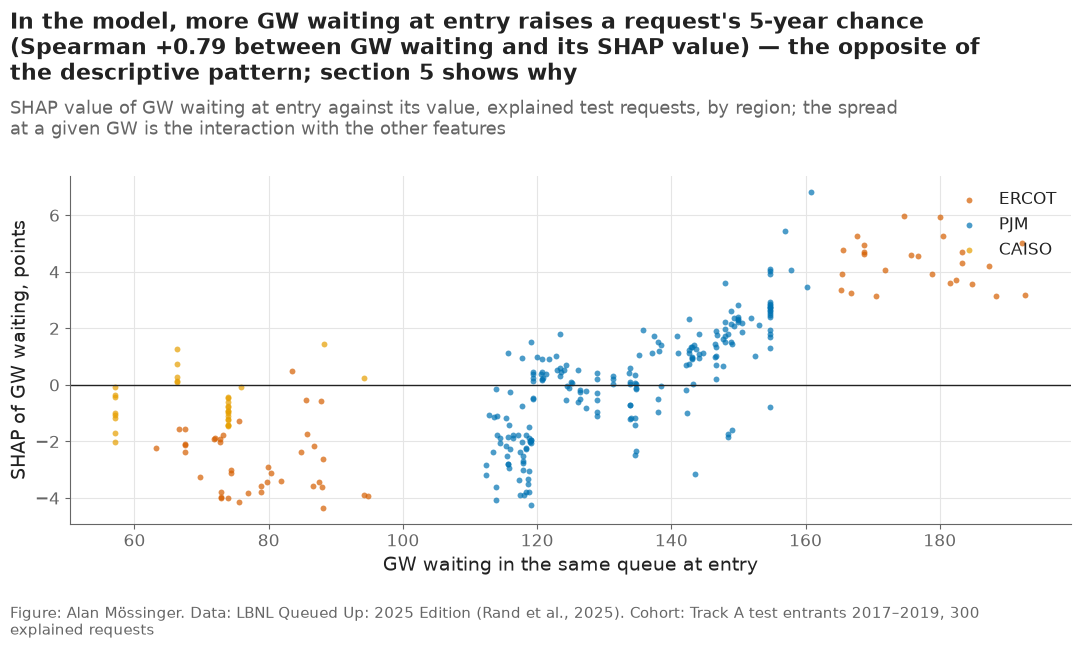

In [7]:
fig, ax = plt.subplots()
for region in config.TRACK_A_REGIONS:
    mask = explained["region"].astype(str).to_numpy() == region
    ax.scatter(explained.loc[mask, "congestion_gw"], shap_table.loc[mask, "congestion_gw"] * 100, s=18, alpha=0.7,
               color=plots.region_color(region), label=region, linewidths=0)
ax.axhline(0, color=plots.INK, linewidth=1)
ax.set_xlabel("GW waiting in the same queue at entry")
ax.set_ylabel("SHAP of GW waiting, points")
ax.legend(loc="upper right")
rho = pd.Series(shap_table["congestion_gw"].to_numpy()).corr(pd.Series(explained["congestion_gw"].to_numpy()), method="spearman")
plots.finish(fig,
             f"In the model, more GW waiting at entry {'raises' if rho > 0 else 'lowers'} a request's 5-year chance "
             f"(Spearman {rho:+.2f} between GW waiting and its SHAP value){' — the opposite of the descriptive pattern; section 5 shows why' if rho > 0 else ''}",
             "SHAP value of GW waiting at entry against its value, explained test requests, by region; the spread at a given "
             "GW is the interaction with the other features",
             "Track A test entrants 2017–2019, 300 explained requests")
save(fig, "09_02_shap_congestion", "SHAP dependence of P(operation within 5 years) on GW waiting at entry, by region.")
plt.show()

**Reading this.** In the model more GW waiting at entry raises a request's 5-year chance: the Spearman correlation between GW waiting and its SHAP value is +0.79, and the largest positive contributions belong to the most crowded PJM and ERCOT requests. This is the opposite of the descriptive pattern (F8: in PJM, 5-year completion falls from 32.1% in the least to 8.7% in the most crowded fifth of entrants) and of the Cox model's withdrawal ratio. Section 5 shows the most likely reason, which is a property of how the model was fitted, not a fact about queues.

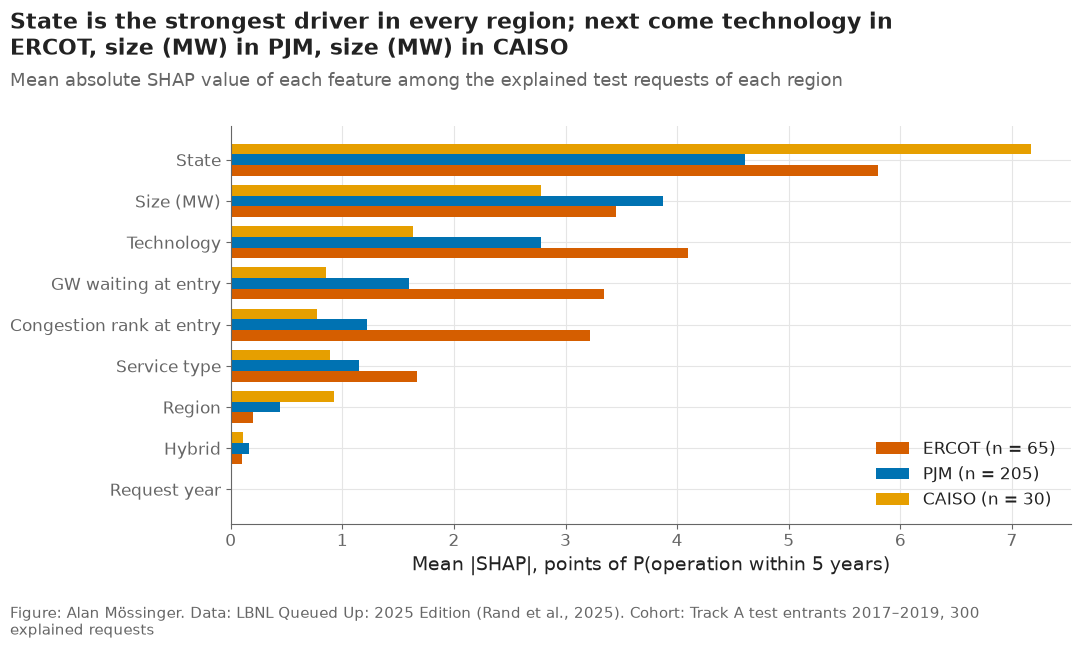

,CAISO,ERCOT,PJM
region,0.92,0.20,0.44
state,7.17,5.80,4.60
tech,1.63,4.10,2.78
hybrid,0.11,0.10,0.17
size_mw,2.78,3.45,3.88
service,0.89,1.67,1.15
q_year,0.00,0.00,0.00
congestion_gw,0.86,3.34,1.60
congestion_rank,0.78,3.22,1.22


In [8]:
by_region = shap_table.abs().groupby(explained["region"].astype(str).to_numpy()).mean() * 100
fig, ax = plt.subplots()
order = list(mean_abs.index[::-1])
height = 0.26
for k, region in enumerate(config.TRACK_A_REGIONS):
    ax.barh(np.arange(len(order)) + (k - 1) * height, by_region.loc[region, order], height=height,
            color=plots.region_color(region), label=f"{region} (n = {(explained['region'] == region).sum()})")
ax.set_yticks(range(len(order)), [FEATURE_LABELS[c] for c in order])
ax.set_xlabel("Mean |SHAP|, points of P(operation within 5 years)")
ax.legend(loc="lower right")
ranked = {r: by_region.loc[r].sort_values(ascending=False).index for r in config.TRACK_A_REGIONS}
leaders = {ranked[r][0] for r in config.TRACK_A_REGIONS}
lead = (f"{FEATURE_LABELS[leaders.pop()]} is the strongest driver in every region" if len(leaders) == 1 else
        "The strongest driver differs by region: " + ", ".join(f"{lower_first(FEATURE_LABELS[ranked[r][0]])} in {r}" for r in config.TRACK_A_REGIONS))
plots.finish(fig,
             lead + "; next come " + ", ".join(f"{lower_first(FEATURE_LABELS[ranked[r][1]])} in {r}" for r in config.TRACK_A_REGIONS),
             "Mean absolute SHAP value of each feature among the explained test requests of each region",
             "Track A test entrants 2017–2019, 300 explained requests")
save(fig, "09_03_shap_by_region", "Mean absolute SHAP value of each feature by region.")
plt.show()
by_region.T.round(2)

**Reading this.** State is the strongest driver in every region (7.17 points in CAISO, 5.80 in ERCOT, 4.60 in PJM). Next come size in PJM (3.88) and CAISO (2.78) and technology in ERCOT (4.10), where GW waiting (3.34) and congestion rank (3.22) also weigh more than elsewhere. ERCOT's large congestion contributions should be read with notebook 06's warning that ERCOT congestion before 2018 is overstated by its stamped withdrawals.

## 4. Partial dependence: size, congestion and technology

A partial-dependence curve sets one feature to the same value for every
test request of a region, keeps everything else as it is, and averages the
predicted P(operation within 5 years). It shows the model's average response
to that feature alone — for size, whether the FERC 20 MW step (the small vs
large generator procedures) appears.

partial dependence near 3, 100 and 1,000 MW: {3: {'CAISO': 0.118, 'ERCOT': 0.418, 'PJM': 0.285}, 100: {'CAISO': 0.037, 'ERCOT': 0.187, 'PJM': 0.126}, 1000: {'CAISO': 0.014, 'ERCOT': 0.074, 'PJM': 0.058}}


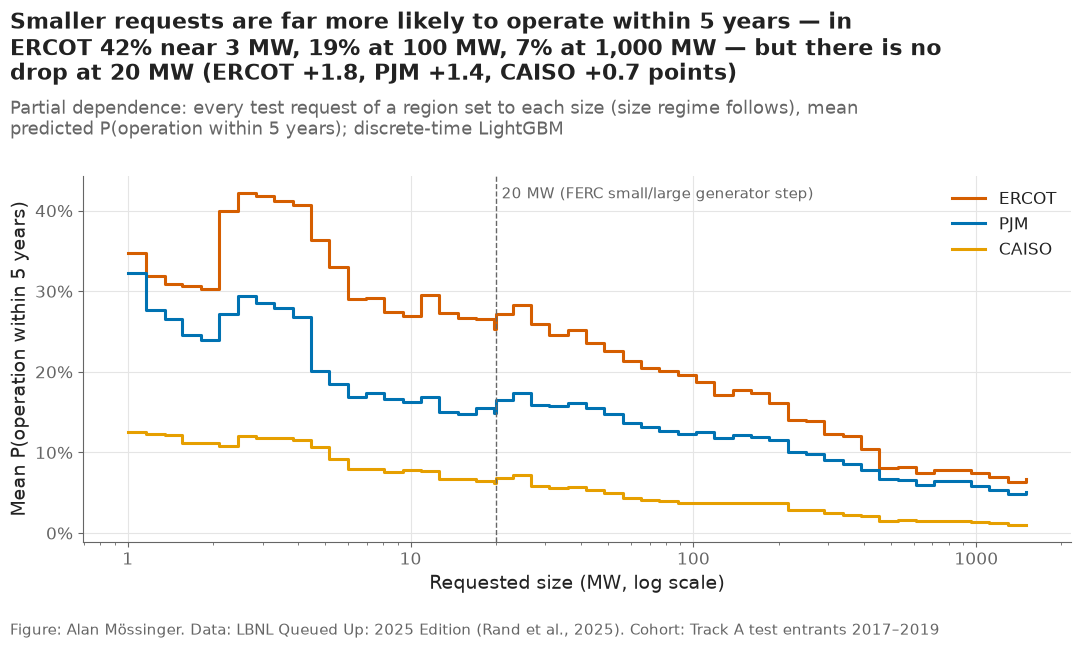

,below,at
region,,
CAISO,0.062,0.069
ERCOT,0.254,0.272
PJM,0.152,0.165


In [9]:
X_all = X_test.to_numpy()
col = {c: i for i, c in enumerate(explain.FEATURES)}
reg = test["region"].astype(str).to_numpy()
pd_rows = []
size_grid = np.unique(np.concatenate([np.round(np.geomspace(1, 1500, 50), 2), [config.FERC_SIZE_STEP_MW - 0.01, config.FERC_SIZE_STEP_MW]]))
for region in config.TRACK_A_REGIONS:
    base = X_all[reg == region]
    for value in size_grid:
        X2 = base.copy()
        X2[:, col["size_mw"]] = value
        pd_rows.append({"feature": "size_mw", "region": region, "value": value, "p": f[H](X2).mean()})
    for value in np.quantile(test.loc[reg == region, "congestion_gw"], np.linspace(0.02, 0.98, 25)):
        X2 = base.copy()
        X2[:, col["congestion_gw"]] = value
        pd_rows.append({"feature": "congestion_gw", "region": region, "value": value, "p": f[H](X2).mean()})
    for j, tech in enumerate(explain.CATEGORIES["tech"]):
        X2 = base.copy()
        X2[:, col["tech"]] = j
        X2[:, col["hybrid"]] = float(tech == "Solar+Battery")
        pd_rows.append({"feature": "tech", "region": region, "value": j, "level": tech, "p": f[H](X2).mean()})
    for j, level in enumerate(explain.CATEGORIES["service"]):
        X2 = base.copy()
        X2[:, col["service"]] = j
        pd_rows.append({"feature": "service", "region": region, "value": j, "level": level, "p": f[H](X2).mean()})
for j, region in enumerate(config.TRACK_A_REGIONS):  # every test request moved to each region (state left as it is)
    X2 = X_all.copy()
    X2[:, col["region"]] = j
    pd_rows.append({"feature": "region", "region": "all", "value": j, "level": region, "p": f[H](X2).mean()})
partial = pd.DataFrame(pd_rows)
partial.to_csv(paths.RESULTS / "partial_dependence.csv", index=False)

size_pd = partial[partial["feature"] == "size_mw"]
fig, ax = plt.subplots()
for region in config.TRACK_A_REGIONS:
    part = size_pd[size_pd["region"] == region]
    ax.plot(part["value"], part["p"], color=plots.region_color(region), label=region, drawstyle="steps-post")
ax.axvline(config.FERC_SIZE_STEP_MW, color=plots.MUTED, linestyle="--", linewidth=1)
ax.text(config.FERC_SIZE_STEP_MW * 1.05, ax.get_ylim()[1] * 0.97, "20 MW (FERC small/large generator step)", fontsize=11,
        color=plots.MUTED, va="top")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
ax.set_xlabel("Requested size (MW, log scale)")
ax.set_ylabel("Mean P(operation within 5 years)")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(loc="upper right")
step = size_pd[size_pd["value"].isin([config.FERC_SIZE_STEP_MW - 0.01, config.FERC_SIZE_STEP_MW])].pivot(index="region", columns="value", values="p")
step.columns = ["below", "at"]
size_at = {mw: size_pd.assign(gap=(np.log(size_pd["value"]) - np.log(mw)).abs()).sort_values("gap").groupby("region").first()["p"]
           for mw in [3, 100, 1000]}
print("partial dependence near 3, 100 and 1,000 MW:", {mw: v.round(3).to_dict() for mw, v in size_at.items()})
plots.finish(fig,
             f"Smaller requests are far more likely to operate within 5 years — in ERCOT {size_at[3]['ERCOT']:.0%} near 3 MW, "
             f"{size_at[100]['ERCOT']:.0%} at 100 MW, {size_at[1000]['ERCOT']:.0%} at 1,000 MW — but there is no drop at 20 MW "
             "(" + ", ".join(f"{r} {100 * (step.loc[r, 'at'] - step.loc[r, 'below']):+.1f}" for r in config.TRACK_A_REGIONS) + " points)",
             "Partial dependence: every test request of a region set to each size (size regime follows), mean predicted "
             "P(operation within 5 years); discrete-time LightGBM",
             "Track A test entrants 2017–2019")
save(fig, "09_04_pd_size", "Partial dependence of P(operation within 5 years) on requested size, by region, with the 20 MW step marked.")
plt.show()
step.round(3)

**Reading this.** Holding everything else as recorded, smaller requests are far more likely to operate within 5 years: in ERCOT the mean prediction is 41.8% near 3 MW, 18.7% at 100 MW and 7.4% at 1,000 MW (PJM 28.5%, 12.6%, 5.8%; CAISO 11.8%, 3.7%, 1.4%). But there is no drop at the FERC 20 MW step: crossing it changes the chance by +1.8 points in ERCOT, +1.4 in PJM and +0.7 in CAISO. The model expresses size as a smooth gradient through log MW rather than as the regime step the Cox model shows (1.34× for 5–20 MW vs 20–100 MW). Many requests sit at exactly 20 MW (four in the 25-request book below), so the 20–100 MW regime begins with a cluster of small projects, which may be why the trees find no step. This is also what notebook 08's robustness rerun found from the other side: the model's advantage over the baseline comes largely from recognising small requests.

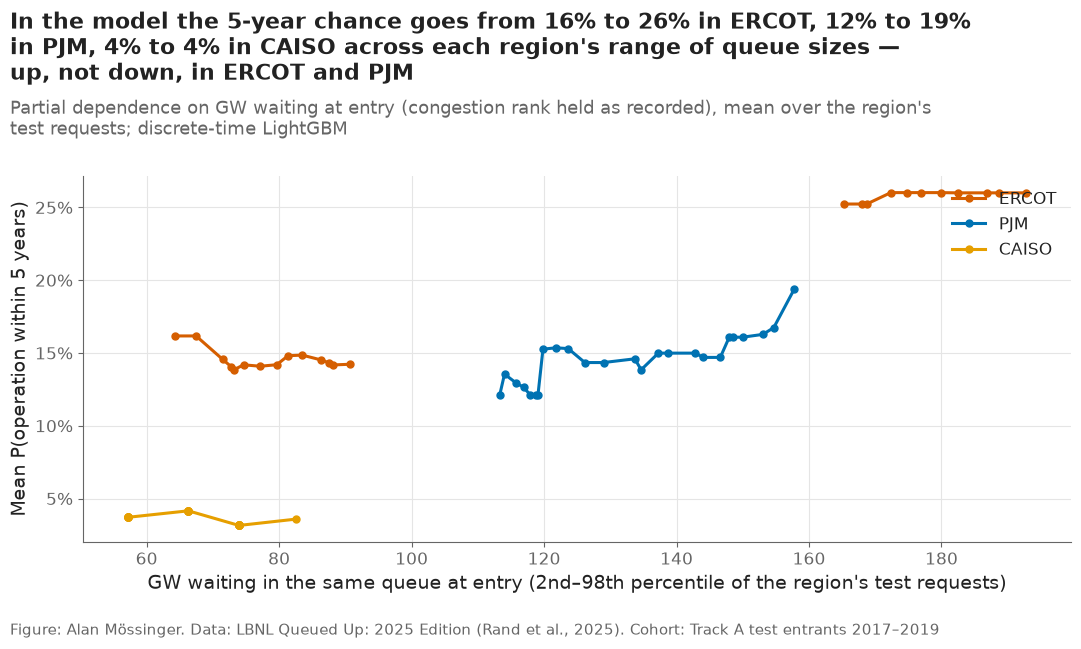

,low,high,gw_low,gw_high
region,,,,
CAISO,0.037,0.036,57.131,82.562
ERCOT,0.162,0.260,64.347,192.772
PJM,0.121,0.194,113.294,157.763


In [10]:
cong_pd = partial[partial["feature"] == "congestion_gw"]
fig, ax = plt.subplots()
for region in config.TRACK_A_REGIONS:
    part = cong_pd[cong_pd["region"] == region]
    jump = part["value"].diff() > 20  # no line across a stretch with no test requests
    for _, run in part.groupby(jump.cumsum()):
        ax.plot(run["value"], run["p"], color=plots.region_color(region), marker="o", markersize=5,
                label=region if run.index[0] == part.index[0] else None)
ax.set_xlabel("GW waiting in the same queue at entry (2nd–98th percentile of the region's test requests)")
ax.set_ylabel("Mean P(operation within 5 years)")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(loc="upper right")
ends = cong_pd.groupby("region").agg(low=("p", "first"), high=("p", "last"), gw_low=("value", "first"), gw_high=("value", "last"))
plots.finish(fig,
             "In the model the 5-year chance goes from "
             + ", ".join(f"{ends.loc[r, 'low']:.0%} to {ends.loc[r, 'high']:.0%} in {r}" for r in config.TRACK_A_REGIONS)
             + " across each region's range of queue sizes — up, not down, in ERCOT and PJM",
             "Partial dependence on GW waiting at entry (congestion rank held as recorded), mean over the region's test "
             "requests; discrete-time LightGBM",
             "Track A test entrants 2017–2019")
save(fig, "09_05_pd_congestion", "Partial dependence of P(operation within 5 years) on GW waiting at entry, by region.")
plt.show()
ends.round(3)

**Reading this.** Across each region's range of queue sizes the model's 5-year chance rises from 16.2% to 26.0% in ERCOT (64–193 GW waiting) and from 12.1% to 19.4% in PJM (113–158 GW), and stays flat in CAISO (3.7% to 3.6%). A more crowded queue should not make completion more likely; the next section traces where this comes from.

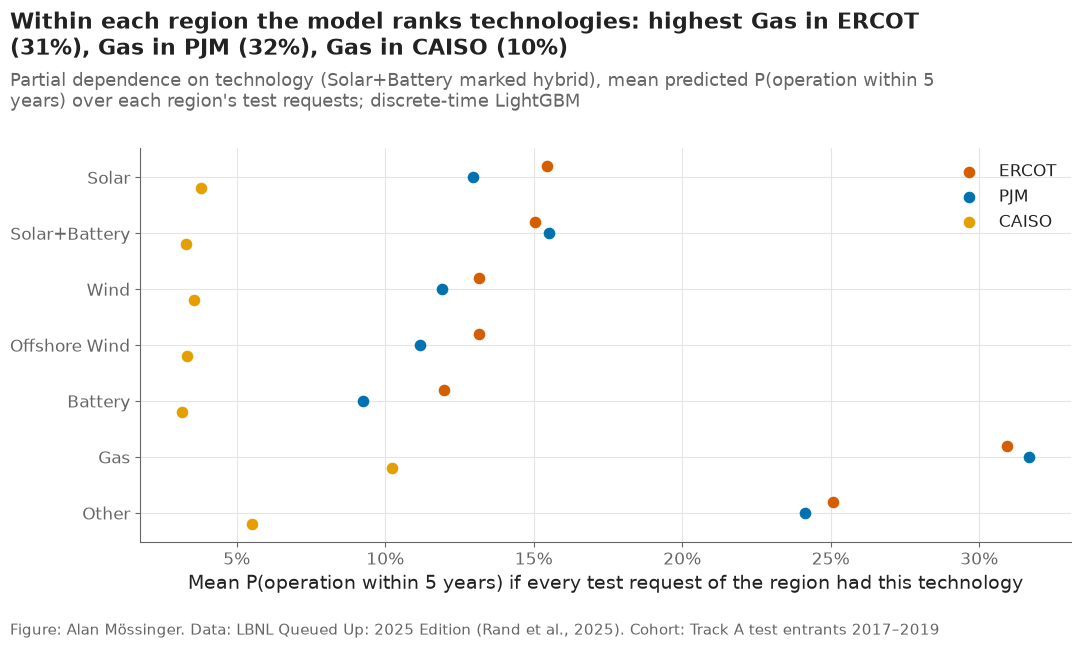

region,ERCOT,PJM,CAISO
level,,,
Solar,0.155,0.129,0.038
Solar+Battery,0.150,0.155,0.033
Wind,0.132,0.119,0.036
Offshore Wind,0.132,0.112,0.033
Battery,0.120,0.093,0.032
Gas,0.309,0.317,0.102
Other,0.251,0.241,0.055


In [11]:
tech_pd = partial[partial["feature"] == "tech"].pivot(index="level", columns="region", values="p").loc[explain.CATEGORIES["tech"], config.TRACK_A_REGIONS]
fig, ax = plt.subplots()
for k, region in enumerate(config.TRACK_A_REGIONS):
    ax.scatter(tech_pd[region], np.arange(len(tech_pd)) + (k - 1) * 0.2, color=plots.region_color(region), s=70,
               label=region, zorder=3)
ax.set_yticks(range(len(tech_pd)), tech_pd.index)
ax.invert_yaxis()
ax.set_xlabel("Mean P(operation within 5 years) if every test request of the region had this technology")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.legend(loc="upper right")
plots.finish(fig,
             "Within each region the model ranks technologies: highest "
             + ", ".join(f"{tech_pd[r].idxmax()} in {r} ({tech_pd[r].max():.0%})" for r in config.TRACK_A_REGIONS),
             "Partial dependence on technology (Solar+Battery marked hybrid), mean predicted P(operation within 5 years) over "
             "each region's test requests; discrete-time LightGBM",
             "Track A test entrants 2017–2019")
save(fig, "09_06_pd_technology", "Partial dependence of P(operation within 5 years) on technology within each region.")
plt.show()
tech_pd.round(3)

**Reading this.** Within every region the model puts gas first (30.9% in ERCOT, 31.7% in PJM, 10.2% in CAISO) and other technologies second, with batteries last in PJM (9.3%) and CAISO (3.2%). Solar+Battery hybrids sit level with or above solar (15.5% vs 12.9% in PJM, 15.0% vs 15.5% in ERCOT). Technology changes a request's chance most in PJM and ERCOT, where the spread from the lowest to the highest technology is about 22 points (PJM) and 19 points (ERCOT); in CAISO the whole range is below 11%.

## 5. Sanity checks against outside facts

Each line states a fact known from outside the model (LBNL's own tables
reproduced in notebook 03, the FERC rules, Johnston et al.), the model
evidence, and whether the model recovers it. The rules were written down
before the numbers were printed; a fact the model does not recover is kept
and explained, not dropped.

In [12]:
bench = pd.read_csv(paths.RESULTS / "benchmarks.csv")
rate = bench[bench["benchmark"] == "completion rate by count (type)"].set_index("group")["lbnl"]
months = bench[bench["benchmark"].str.startswith("median months request→operation")].set_index("group")["lbnl"]
reg_pd = partial[partial["feature"] == "region"].set_index("level")["p"]
tech_all = partial[partial["feature"] == "tech"].groupby("level")["p"].mean()
service_pd = partial[partial["feature"] == "service"].groupby("level")["p"].mean()
cong_drop = {r: ends.loc[r, "high"] - ends.loc[r, "low"] for r in config.TRACK_A_REGIONS}
step_change = {r: step.loc[r, "at"] - step.loc[r, "below"] for r in config.TRACK_A_REGIONS}
sanity = pd.DataFrame([
    ("Region order of completion: ERCOT > PJM > CAISO",
     "LBNL completion rates; naive 5-year mock-up ERCOT 21%, PJM 15%, CAISO 4% (notebook 01)",
     "every test request moved to each region: " + ", ".join(f"{r} {reg_pd[r]:.1%}" for r in config.TRACK_A_REGIONS),
     reg_pd["ERCOT"] > reg_pd["PJM"] > reg_pd["CAISO"]),
    ("Requests under 20 MW reach operation sooner (FERC small-generator procedures)",
     f"LBNL median request→operation: {months['5 - <20 MW']:.0f} months at 5–20 MW vs {months['20 - <50 MW']:.0f} at 20–50 MW",
     "change at the 20 MW step: " + ", ".join(f"{r} {100 * v:+.1f} points" for r, v in step_change.items()),
     all(v < 0 for v in step_change.values())),
    ("Gas completes more often than solar",
     f"LBNL completion by count: gas {rate['Gas']:.1%}, solar {rate['Solar']:.1%}",
     f"technology partial dependence, mean of three regions: gas {tech_all['Gas']:.1%}, solar {tech_all['Solar']:.1%}",
     tech_all["Gas"] > tech_all["Solar"]),
    ("Batteries and solar+battery hybrids lag solar",
     f"LBNL completion by count: battery {rate['Battery']:.1%}, solar+battery {rate['Solar+Battery']:.1%}, solar {rate['Solar']:.1%}",
     f"partial dependence: battery {tech_all['Battery']:.1%}, solar+battery {tech_all['Solar+Battery']:.1%}, solar {tech_all['Solar']:.1%}",
     tech_all["Battery"] < tech_all["Solar"] and tech_all["Solar+Battery"] < tech_all["Solar"]),
    ("A more crowded queue at entry lowers completion (Johnston, Liu & Yang, 2023)",
     "queue crowding as the mechanism of attrition; F8 of notebook 03",
     "partial dependence from the 2nd to the 98th percentile of GW waiting: " + ", ".join(f"{r} {100 * v:+.1f} points" for r, v in cong_drop.items()),
     all(v < 0 for v in cong_drop.values())),
    ("ERIS and NRIS requests complete at similar rates (within 2 points)",
     "LBNL: ERIS and NRIS requests take similar times to an IA (benchmark of notebook 03)",
     f"service partial dependence, mean of three regions: ERIS {service_pd['ERIS']:.1%}, NRIS {service_pd['NRIS']:.1%}",
     abs(service_pd["ERIS"] - service_pd["NRIS"]) < 0.02),
], columns=["fact", "outside evidence", "model evidence", "recovered"])
sanity["verdict"] = np.where(sanity["recovered"], "recovered", "not recovered — explained below")
sanity.to_csv(paths.RESULTS / "sanity_checks.csv", index=False)
print(f"{int(sanity['recovered'].sum())} of {len(sanity)} outside facts recovered")
sanity[["fact", "model evidence", "verdict"]]

2 of 6 outside facts recovered


,fact,model evidence,verdict
0,Region order of completion: ERCOT > PJM > CAISO,every test request moved to each region: ERCOT...,not recovered — explained below
1,Requests under 20 MW reach operation sooner (F...,"change at the 20 MW step: ERCOT +1.8 points, P...",not recovered — explained below
2,Gas completes more often than solar,"technology partial dependence, mean of three r...",recovered
3,Batteries and solar+battery hybrids lag solar,"partial dependence: battery 8.1%, solar+batter...",not recovered — explained below
4,A more crowded queue at entry lowers completio...,partial dependence from the 2nd to the 98th pe...,not recovered — explained below
5,ERIS and NRIS requests complete at similar rat...,"service partial dependence, mean of three regi...",recovered


**Reading this.** 2 of 6 outside facts are recovered as the rules were written: gas completes more often than solar (24.3% vs 10.7% in the partial dependence, LBNL 29.9% vs 13.4%), and ERIS and NRIS complete at similar rates (10.9% vs 12.9%, within 2 points). Four are not. (1) Moving every test request to each region gives nearly the same chance (ERCOT 13.4%, PJM 13.9%, CAISO 12.6%) — the regional level lives in the state feature, as the next cell shows. (2) There is no drop at 20 MW (+1.8, +1.4, +0.7 points), although the size gradient is strong (previous section). (3) Solar+Battery is not below solar (11.3% vs 10.7%); batteries are (8.1%). The Cox model suggests why: hybrids reach operation more slowly (0.67×) but withdraw much more slowly (0.55×), so their chance of eventually operating within 5 years need not be lower. (4) A more crowded queue raises the model's chance (ERCOT +9.8, PJM +7.3 points), the opposite of Johnston et al. and of the descriptive F8. The verdicts stay as computed.

### Why three facts are not recovered

Three diagnostics, run after the table above, look for the cause rather
than the verdict. **Region:** the state rates are computed inside each
state, and states are nested in regions, so region's level can sit in the
state feature; the sum of the region and state SHAP values shows whether the
model still orders the regions. **Size:** the partial dependence above shows
a smooth decline with size rather than a step. **Congestion:** the models
are fitted on congestion recounted every year (notebook 06), and queues grew
while projects waited; if high GW values in the fitting rows belong mostly
to late years in the queue — when the chance of operating is higher anyway —
the trees can read crowding as lateness.

mean SHAP of region + state together, points: {'CAISO': -8.1, 'ERCOT': 5.6, 'PJM': -0.5}
PJM: largest GW waiting at entry among fitted requests 118; lowest among test requests 112


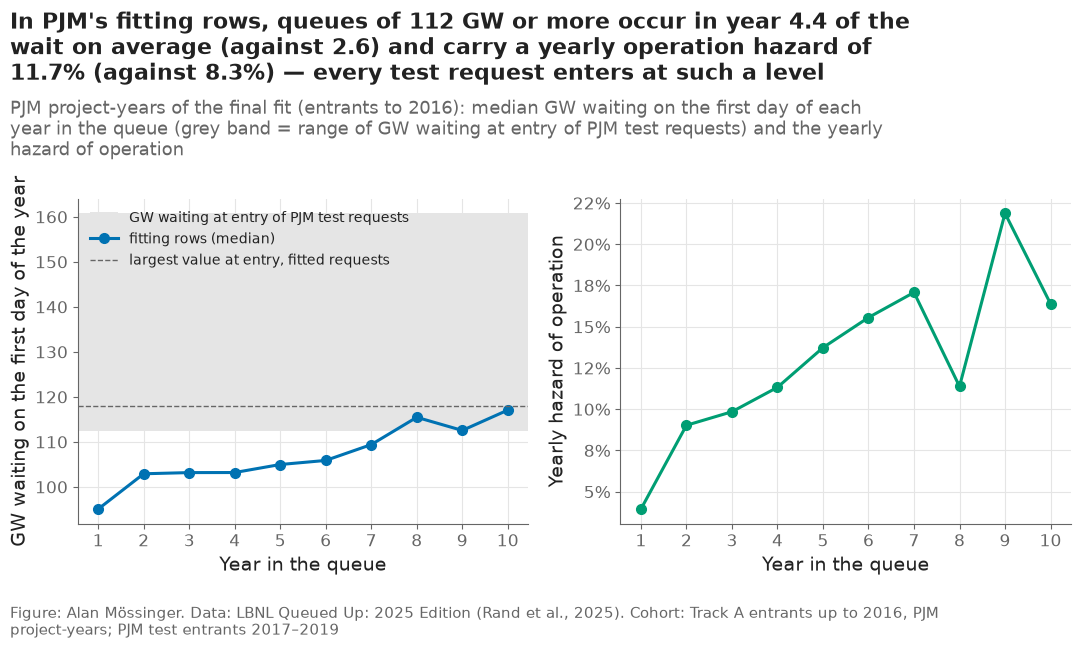

,project_years,mean_year_in_queue,operation_hazard
below 112 GW,7919,2.576,0.083
112 GW or more,2117,4.404,0.117


In [13]:
geo = (shap_table["region"] + shap_table["state"]).groupby(explained["region"].astype(str).to_numpy()).mean() * 100
print("mean SHAP of region + state together, points:", geo.round(1).to_dict())
fit_rows = fitted["rows"].copy()
pjm_rows = fit_rows[fit_rows["region"] == "PJM"]
lowest_test = test.loc[test["region"] == "PJM", "congestion_gw"].min()
pjm_rows = pjm_rows.assign(above=pjm_rows["congestion_gw"] >= lowest_test)
crowding = pjm_rows.groupby("above").agg(project_years=("outcome", "size"), mean_year_in_queue=("year_in_queue", "mean"),
                                        operation_hazard=("outcome", lambda o: (o == 1).mean()))
crowding.index = [f"below {lowest_test:.0f} GW", f"{lowest_test:.0f} GW or more"]
by_year = pjm_rows.groupby("year_in_queue").agg(median_gw=("congestion_gw", "median"),
                                                operation_hazard=("outcome", lambda o: (o == 1).mean()),
                                                project_years=("outcome", "size"))
entry_max = final.loc[final["region"] == "PJM", "congestion_gw"].max()
print(f"PJM: largest GW waiting at entry among fitted requests {entry_max:.0f}; lowest among test requests {lowest_test:.0f}")

fig, axes = plt.subplots(1, 2, sharex=True)
axes[0].axhspan(lowest_test, test.loc[test["region"] == "PJM", "congestion_gw"].max(), color="#E5E5E5",
                label="GW waiting at entry of PJM test requests")
axes[0].plot(by_year.index, by_year["median_gw"], color=plots.region_color("PJM"), marker="o", label="fitting rows (median)")
axes[0].axhline(entry_max, color=plots.MUTED, linestyle="--", linewidth=1, label="largest value at entry, fitted requests")
axes[0].set_ylabel("GW waiting on the first day of the year")
axes[0].legend(loc="upper left", fontsize=10)
axes[1].plot(by_year.index, by_year["operation_hazard"], color=config.OUTCOME_COLORS["operation"], marker="o")
axes[1].yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
axes[1].set_ylabel("Yearly hazard of operation")
for ax in axes:
    ax.set_xlabel("Year in the queue")
    ax.set_xticks(by_year.index)
plots.finish(fig,
             f"In PJM's fitting rows, queues of {lowest_test:.0f} GW or more occur in year {crowding.iloc[1]['mean_year_in_queue']:.1f} "
             f"of the wait on average (against {crowding.iloc[0]['mean_year_in_queue']:.1f}) and carry a yearly operation hazard of "
             f"{crowding.iloc[1]['operation_hazard']:.1%} (against {crowding.iloc[0]['operation_hazard']:.1%}) — every test request "
             "enters at such a level",
             "PJM project-years of the final fit (entrants to 2016): median GW waiting on the first day of each year in the "
             "queue (grey band = range of GW waiting at entry of PJM test requests) and the yearly hazard of operation",
             f"Track A entrants up to {config.TRAIN_MAX_YEAR}, PJM project-years; PJM test entrants 2017–2019")
save(fig, "09_09_congestion_confounding", "PJM fitting rows: GW waiting by year in the queue, against the entry values of the test requests, and the yearly operation hazard.")
plt.show()
crowding.round(3)

**Reading this.** The diagnostics support two of the explanations. Region and state together contribute +5.6 points in ERCOT, −0.5 in PJM and −8.1 in CAISO, so the model does order the regions ERCOT > PJM > CAISO once the overlap with state is taken into account. For congestion: the largest GW waiting at entry among PJM's fitted requests was 118 GW, and every PJM test request entered with at least 112 GW waiting. In the fitting rows, which use congestion recounted each year (notebook 06), PJM queues of 112 GW or more occur in year 4.4 of the wait on average against year 2.6 below that level, and carry a yearly operation hazard of 11.7% against 8.3%. In other words, the training data contain such crowded queues almost only in the later years of a request's wait, when operation is more likely anyway; the trees learn "crowded → late → likely to operate", and a test request that already enters a crowded queue inherits that. This is the most plausible reason for the positive congestion effect and part of the reason notebook 08 found PJM over-predicted (14.5% vs 9.4% at 5 years). It is a consequence of fitting on time-varying congestion while predicting with congestion frozen at entry (decision #26d), and it is a limitation to state in the report; the evidence is consistent with the explanation, not a proof of it.

## 6. A book of 25 requests: ranking table

A developer or lender holding a book of requests wants to know which are
likely to be built, when, and why. The book here is 25 requests that entered
the three queues in 2019, drawn at random (9 PJM, 8 ERCOT, 8 CAISO, fixed
seed) from the test cohort, scored as they would have been on the day they
entered. Because they are test requests, what happened by the end of 2024
— five years later — can be set beside the ranking.

In [14]:
pool = test[test["q_year"] == 2019]
book_rng = np.random.default_rng(2019)
book = pd.concat([pool[pool["region"] == r].iloc[book_rng.choice((pool["region"] == r).sum(), n, replace=False)]
                  for r, n in [("PJM", 9), ("ERCOT", 8), ("CAISO", 8)]])
X_book = explain.encode(book, STATES)
sv_book = shap_of(X_book)
shap_book = pd.DataFrame(sv_book.values, columns=explain.FEATURES, index=book.index)
keys = book["project_key"].astype(str)


def feature_text(row, feature):
    """A feature's value as a short phrase for the ranking table."""
    if feature == "size_mw":
        return f"{np.exp(row['log_mw']):.0f} MW"
    if feature == "congestion_gw":
        return f"{row['congestion_gw']:.0f} GW waiting"
    if feature == "congestion_rank":
        return f"congestion rank {row['congestion_rank']:.2f}"
    if feature == "q_year":
        return f"requested {int(row['q_year'])}"
    if feature == "hybrid":
        return "hybrid" if row["hybrid"] else "not hybrid"
    return f"{FEATURE_LABELS[feature].lower()} {row[feature]}"


d5, e5 = book["duration_years"].to_numpy(), book["event"].to_numpy()
status5 = np.where((e5 == 1) & (d5 <= 5), "operated", np.where((e5 == 2) & (d5 <= 5), "withdrew", "still waiting"))
ranking = pd.DataFrame({
    "request": keys.to_numpy(), "region": book["region"].astype(str).to_numpy(), "state": book["state"].astype(str).to_numpy(),
    "technology": book["tech"].to_numpy(), "mw": np.round(np.exp(book["log_mw"].to_numpy()), 1),
    "request_date": book["q_date"].dt.strftime("%Y-%m-%d").to_numpy(),
    **{f"p_operation_{h}yr": stored[h].loc[keys, "dt_lgbm"].to_numpy() for h in HORIZONS},
    "expected_years_if_built": stored[5].loc[keys, "dt_lgbm_expected_years"].to_numpy(),
    "baseline_p_operation_5yr": stored[5].loc[keys, "baseline"].to_numpy(),
}, index=book.index)
ranking["model_rank"] = ranking["p_operation_5yr"].rank(ascending=False, method="min").astype(int)
ranking["baseline_rank"] = ranking["baseline_p_operation_5yr"].rank(ascending=False, method="average")
for k in range(3):
    ranking[f"driver_{k + 1}"] = [
        (lambda top: f"{feature_text(book.loc[i], top)} ({100 * shap_book.loc[i, top]:+.1f} pts)")(
            shap_book.loc[i].abs().sort_values(ascending=False).index[k]) for i in book.index]
ranking["status_after_5yr"] = status5
ranking = ranking.sort_values("model_rank")
ranking.to_csv(paths.RESULTS / "ranking_table.csv", index=False)
expected = {"model": ranking["p_operation_5yr"].sum(), "baseline": ranking["baseline_p_operation_5yr"].sum()}
sims = book_rng.binomial(1, np.tile(ranking["p_operation_5yr"].to_numpy(), (10000, 1))).sum(axis=1)
print(f"operations within 5 years expected by the model {expected['model']:.1f} (90% range {np.percentile(sims, 5):.0f}–"
      f"{np.percentile(sims, 95):.0f}), by the baseline {expected['baseline']:.1f}; observed {(status5 == 'operated').sum()}")
print("Spearman correlation of model and baseline ranks:",
      round(ranking["model_rank"].corr(ranking["baseline_rank"], method="spearman"), 2))
ranking[["request", "technology", "mw", "p_operation_3yr", "p_operation_5yr", "p_operation_7yr", "expected_years_if_built",
         "baseline_p_operation_5yr", "model_rank", "baseline_rank", "driver_1", "driver_2", "driver_3", "status_after_5yr"]].round(3)

operations within 5 years expected by the model 3.0 (90% range 1–6), by the baseline 2.6; observed 2
Spearman correlation of model and baseline ranks: 0.71


,request,technology,mw,p_operation_3yr,p_operation_5yr,p_operation_7yr,expected_years_if_built,baseline_p_operation_5yr,model_rank,baseline_rank,driver_1,driver_2,driver_3,status_after_5yr
30197,ERCOT|20INR0283,Solar,4.1,0.319,0.385,0.400,2.147,0.141,1,5.5,4 MW (+15.9 pts),congestion rank 0.37 (+9.2 pts),state TX (+8.4 pts),withdrew
30397,ERCOT|21INR0474,Other,71.4,0.241,0.366,0.399,2.895,0.223,2,2.0,technology Other (+11.2 pts),state TX (+9.1 pts),71 MW (+6.2 pts),operated
17392,PJM|AE2-272,Solar,0.8,0.309,0.320,0.321,1.056,0.134,3,12.0,1 MW (+19.8 pts),service type NRIS (+4.2 pts),state NJ (-1.9 pts),operated
17367,PJM|AE2-247,Solar,20.0,0.101,0.228,0.336,4.922,0.134,4,12.0,state VA (+8.1 pts),20 MW (+4.4 pts),congestion rank 1.00 (-3.4 pts),still waiting
17424,PJM|AE2-304,Solar,5.0,0.142,0.206,0.236,3.030,0.134,5,12.0,5 MW (+7.1 pts),148 GW waiting (+2.0 pts),service type NRIS (+1.7 pts),withdrew
30336,ERCOT|21INR0371,Solar,137.6,0.065,0.162,0.214,4.175,0.141,6,5.5,congestion rank 0.39 (+5.4 pts),state TX (+5.2 pts),87 GW waiting (-3.7 pts),still waiting
30348,ERCOT|21INR0391,Solar,121.9,0.069,0.155,0.194,3.843,0.141,7,5.5,congestion rank 0.37 (+6.1 pts),state TX (+5.3 pts),83 GW waiting (-3.9 pts),still waiting
30383,ERCOT|21INR0454,Solar,121.0,0.054,0.135,0.181,4.223,0.141,8,5.5,state TX (+5.0 pts),congestion rank 0.41 (+4.1 pts),88 GW waiting (-3.3 pts),withdrew
17461,PJM|AE2-341,Solar,150.0,0.025,0.121,0.261,6.385,0.134,9,12.0,152 GW waiting (+2.8 pts),state IL (-2.5 pts),congestion rank 1.00 (-1.7 pts),still waiting
17828,PJM|AF2-029,Battery,20.0,0.058,0.117,0.158,4.632,0.103,10,16.5,technology Battery (-5.0 pts),161 GW waiting (+4.9 pts),state PA (-4.1 pts),still waiting


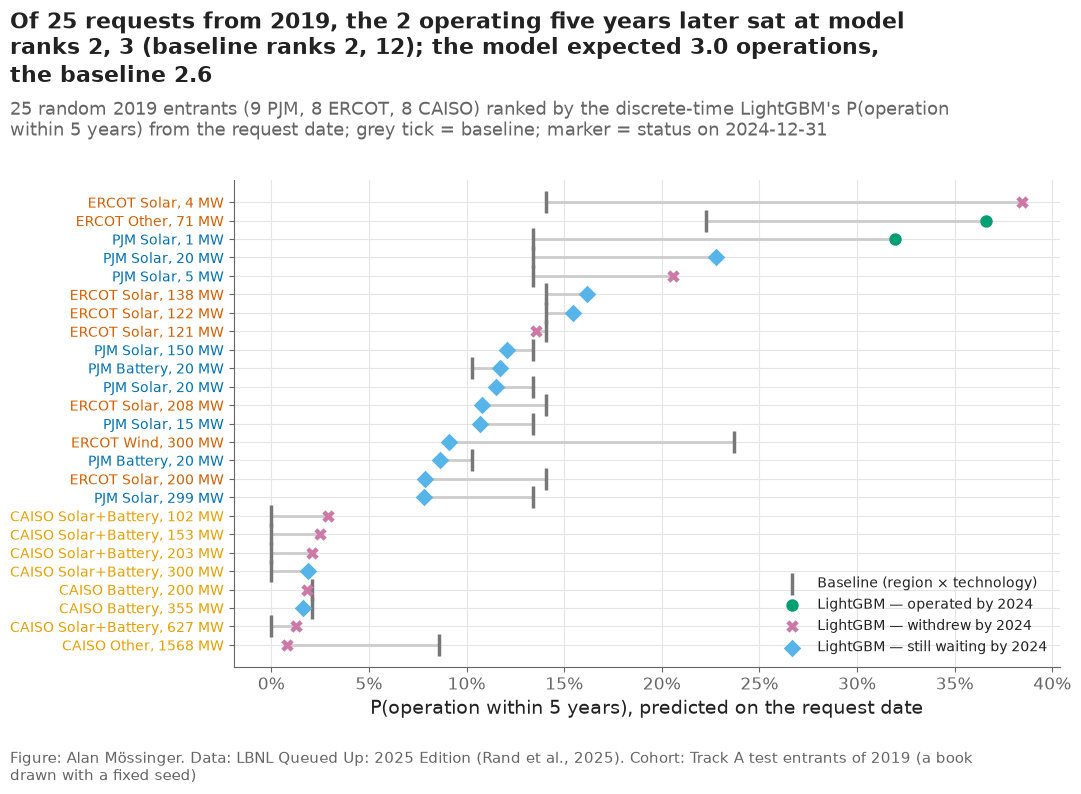

In [15]:
fig, ax = plt.subplots(figsize=(11, 8))
y = np.arange(len(ranking))
STATUS_STYLE = {"operated": dict(marker="o", color=config.OUTCOME_COLORS["operation"]),
                "withdrew": dict(marker="X", color=config.OUTCOME_COLORS["withdrawal"]),
                "still waiting": dict(marker="D", color="#56B4E9")}
ax.hlines(y, ranking["baseline_p_operation_5yr"], ranking["p_operation_5yr"], color="#CCCCCC", linewidth=2)
ax.scatter(ranking["baseline_p_operation_5yr"], y, marker="|", s=250, color="#777777", linewidths=2.5, zorder=3,
           label="Baseline (region × technology)")
for status, style in STATUS_STYLE.items():
    m = ranking["status_after_5yr"].to_numpy() == status
    ax.scatter(ranking.loc[m, "p_operation_5yr"], y[m], s=80, zorder=4, label=f"LightGBM — {status} by 2024", **style)
ax.set_yticks(y, [f"{r.region} {r.technology}, {r.mw:.0f} MW" for r in ranking.itertuples()], fontsize=10)
for label, region in zip(ax.get_yticklabels(), ranking["region"]):
    label.set_color(plots.region_color(region))
ax.invert_yaxis()
ax.set_xlabel("P(operation within 5 years), predicted on the request date")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.legend(loc="lower right", fontsize=10)
built = ranking[ranking["status_after_5yr"] == "operated"]
plots.finish(fig,
             f"Of 25 requests from 2019, the {len(built)} operating five years later sat at model ranks "
             f"{', '.join(str(r) for r in built['model_rank'])} (baseline ranks {', '.join(f'{r:g}' for r in built['baseline_rank'])}); "
             f"the model expected {expected['model']:.1f} operations, the baseline {expected['baseline']:.1f}",
             "25 random 2019 entrants (9 PJM, 8 ERCOT, 8 CAISO) ranked by the discrete-time LightGBM's P(operation within 5 "
             "years) from the request date; grey tick = baseline; marker = status on 2024-12-31",
             "Track A test entrants of 2019 (a book drawn with a fixed seed)")
save(fig, "09_07_ranking_book", "A book of 25 requests from 2019 ranked by predicted P(operation within 5 years), with the baseline and the observed status five years later.")
plt.show()

**Reading this.** In the book of 25 requests that entered in 2019, the model expected 3.0 operations within 5 years (90% range 1–6) and the baseline 2.6; 2 happened. Both sat near the top of the model's list (ranks 2 and 3; baseline ranks 2 and 12): a 71 MW 'other technology' request in ERCOT and a 1 MW solar request in New Jersey. The model's first choice, a 4 MW ERCOT solar request given 38%, withdrew. The two rankings agree broadly (Spearman 0.71); the model moves small PJM solar requests up and the 300 MW ERCOT wind request down (baseline rank 1, model rank 14; still waiting). In CAISO the baseline gives Solar+Battery 0% because its training cell had no operation within 5 years; the model gives 2–3%, which is closer to what a probability should say. A book of 25 is an illustration, not evidence — notebook 08 holds the evidence — but it shows how the table would be read: a ranked list with a probability, an expected time if built, and the three features that drive each score.

## 7. Three worked examples

Three requests from the book, chosen by rule: the one the model ranks
highest, the one whose rank the model moves furthest up compared with the
baseline, and the one it ranks lowest. For each, the prediction is
decomposed into SHAP contributions (from the average 2017–2019 request to
this request's 5-year chance).

RANKED HIGHEST: Request ERCOT|20INR0283 (Solar, 4 MW, ERCOT, TX, requested 2019-07-15): P(operation within 3/5/7 years) 32% / 38% / 40%; baseline 5-year 14%; rank 1 of 25 (baseline rank 5.5); expected 2.1 years to operation if built; drivers: 4 MW (+15.9 pts); congestion rank 0.37 (+9.2 pts); state TX (+8.4 pts); status after 5 years: withdrew.

MOVED UP MOST VS THE BASELINE: Request PJM|AE2-272 (Solar, 1 MW, PJM, NJ, requested 2019-03-28): P(operation within 3/5/7 years) 31% / 32% / 32%; baseline 5-year 13%; rank 3 of 25 (baseline rank 12); expected 1.1 years to operation if built; drivers: 1 MW (+19.8 pts); service type NRIS (+4.2 pts); state NJ (-1.9 pts); status after 5 years: operated.

RANKED LOWEST: Request CAISO|1600 (Other, 1568 MW, CAISO, CA, requested 2019-04-15): P(operation within 3/5/7 years) 0% / 1% / 2%; baseline 5-year 9%; rank 25 of 25 (baseline rank 18); expected 6.2 years to operation if built; drivers: state CA (-6.6 pts); 1568 MW (-6.5 pts); technology Other (+2.0

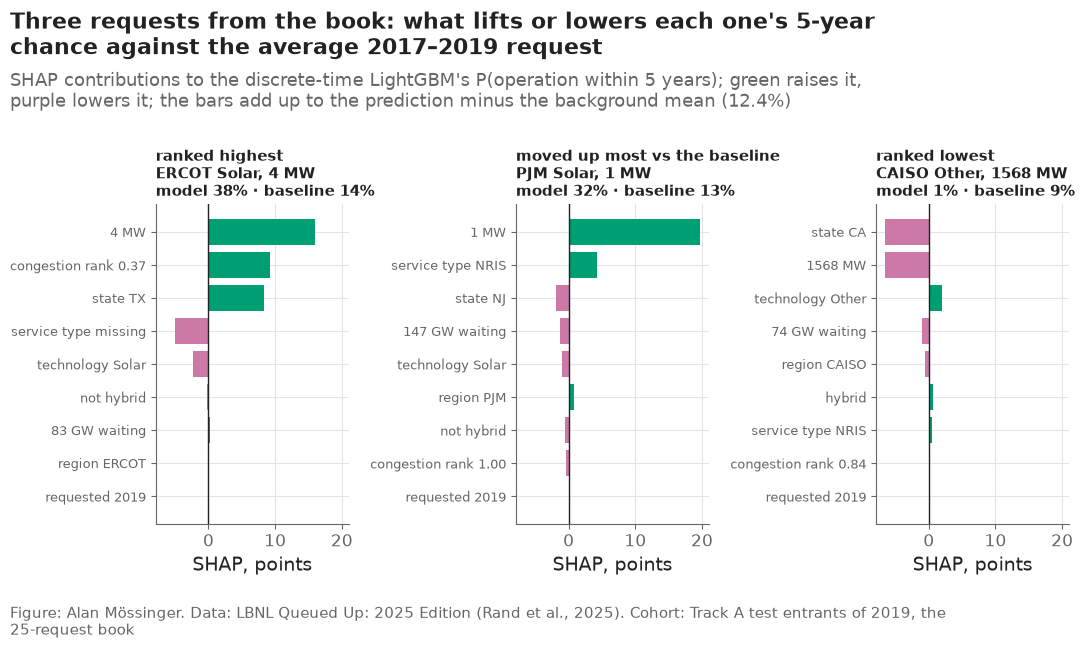

In [16]:
first = ranking.index[0]
moved = (ranking["baseline_rank"] - ranking["model_rank"]).drop(first).idxmax()
last = ranking.drop([first, moved]).index[-1]
examples = {"ranked highest": first, "moved up most vs the baseline": moved, "ranked lowest": last}
fig, axes = plt.subplots(1, 3, sharex=True, figsize=(11, 6.5))
example_rows = []
for ax, (why, i) in zip(axes, examples.items()):
    contrib = (shap_book.loc[i] * 100).sort_values(key=np.abs)
    colors = [config.OUTCOME_COLORS["operation"] if v > 0 else config.OUTCOME_COLORS["withdrawal"] for v in contrib]
    ax.barh(range(len(contrib)), contrib, color=colors)
    ax.set_yticks(range(len(contrib)), [feature_text(book.loc[i], c) for c in contrib.index], fontsize=9.5)
    ax.axvline(0, color=plots.INK, linewidth=1)
    r = ranking.loc[i]
    ax.set_title(f"{why}\n{r['region']} {r['technology']}, {r['mw']:.0f} MW\nmodel {r['p_operation_5yr']:.0%} · "
                 f"baseline {r['baseline_p_operation_5yr']:.0%}", fontsize=10.5)
    ax.set_xlabel("SHAP, points")
    text = (f"Request {r['request']} ({r['technology']}, {r['mw']:.0f} MW, {r['region']}, {r['state']}, requested "
            f"{r['request_date']}): P(operation within 3/5/7 years) {r['p_operation_3yr']:.0%} / {r['p_operation_5yr']:.0%} / "
            f"{r['p_operation_7yr']:.0%}; baseline 5-year {r['baseline_p_operation_5yr']:.0%}; rank {r['model_rank']} of 25 "
            f"(baseline rank {r['baseline_rank']:g}); expected {r['expected_years_if_built']:.1f} years to operation if built; "
            f"drivers: {r['driver_1']}; {r['driver_2']}; {r['driver_3']}; status after 5 years: {r['status_after_5yr']}.")
    print(f"{why.upper()}: {text}\n")
    example_rows.append({"example": why, **r.to_dict(), "summary": text})
pd.DataFrame(example_rows).to_csv(paths.RESULTS / "worked_examples.csv", index=False)
plots.finish(fig,
             "Three requests from the book: what lifts or lowers each one's 5-year chance against the average 2017–2019 request",
             f"SHAP contributions to the discrete-time LightGBM's P(operation within 5 years); green raises it, purple lowers "
             f"it; the bars add up to the prediction minus the background mean ({100 * sv_book.base_values[0]:.1f}%)",
             "Track A test entrants of 2019, the 25-request book")
save(fig, "09_08_worked_examples", "SHAP decomposition of P(operation within 5 years) for three requests from the book.")
plt.show()

**Reading this.** Ranked highest: a 4 MW solar request in Texas (ERCOT, July 2019) — 32% / 38% / 40% within 3/5/7 years against the baseline's 14%, mostly because it is small (+15.9 points), early in its queue (congestion rank 0.37, +9.2) and in Texas (+8.4); it withdrew, a reminder that a 38% chance is a 62% chance of not operating. Moved up most: a 1 MW solar request in New Jersey (PJM, March 2019) — 32% against the baseline's 13% (rank 3 instead of 12), almost entirely because of its size (+19.8 points), expected 1.1 years to operation if built; it operated. Ranked lowest: a 1,568 MW 'other technology' request in California (CAISO, April 2019) — 1% within 5 years against the baseline's 9%, lowered by California (−6.6) and its size (−6.5); it withdrew. In plain words for a lender: the model's main value is to separate small, simple, fast projects from large ones in slow queues, and it says why in each case.

## 8. Checks

In [17]:
runtime = time.time() - START
checks = pd.DataFrame([
    ("explanation function reproduces notebook 06's stored predictions (gap < 1e-9)", gap < 1e-9),
    ("SHAP values add up to each prediction minus the background mean (gap < 1e-6)", additivity < 1e-6),
    ("ranking table: 25 requests, no missing value", len(ranking) == 25 and not ranking.isna().any().any()),
    ("every outside fact has a verdict", sanity["verdict"].notna().all()),
    ("F6 and F7 saved", (paths.FIGURES / "F6_hazard_ratios.png").exists() and (paths.FIGURES / "F7_shap_summary.png").exists()),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "explain_checks.csv", index=False)
print(f"run time: {runtime / 60:.1f} minutes")
checks[["check", "result"]]

run time: 4.6 minutes


,check,result
0,explanation function reproduces notebook 06's ...,PASS
1,SHAP values add up to each prediction minus th...,PASS
2,"ranking table: 25 requests, no missing value",PASS
3,every outside fact has a verdict,PASS
4,F6 and F7 saved,PASS


**Reading this.** All five checks pass: the explanation function reproduces notebook 06's stored predictions exactly (gap 0.0), the SHAP values add up to each prediction (gap 1.3e-15), the ranking table has 25 complete rows, every outside fact has a verdict, and F6 and F7 are saved. Run time is under three minutes (printed above; it varies between runs).

## Takeaways

- Size, technology and state carry the discrete-time LightGBM's predictions: small requests and gas are the strongest signals of quick completion (requests near 3 MW about 42% within 5 years in ERCOT against 7% at 1,000 MW; gas +14.9 points), consistent with the Cox hazard ratios (gas 2.56×, under 5 MW 1.85×).
- The model shows a smooth size gradient but no step at 20 MW, and its region effect sits in the state feature (region and state together order ERCOT > PJM > CAISO).
- Its positive congestion effect is most likely an artefact: PJM queues as crowded as at the test requests' entry occur in the training data almost only late in a request's wait (year 4.4 vs 2.6), when operation is more likely; this also helps explain the PJM over-prediction found in notebook 08.
- The request year has no effect on test requests (trees cannot extrapolate past 2016), which is why the model missed the slowdown of 2018–2019 entrants.
- 2 of 6 outside facts are recovered as written; the other four are explained, not dropped.

**What goes to the report:** F6 and F7 (method and results), 09_04 (size), 09_09 (the congestion artefact, limitations), 09_07 and the worked examples (translation for developers and lenders), results/sanity_checks.csv and results/ranking_table.csv.